# ResNet50

Run `01_Preprocessing.ipynb` first. Each notebook is independent. The first run may download pretrained weights. For a quick smoke test change HEAD_EPOCHS=1, FINE_TUNE_EPOCHS=0. **Do not report smoke tests as final scientific results.**

In [1]:
from derm_training import resolve_data, train_one
import pandas as pd
from IPython.display import display

df=resolve_data()
display(pd.crosstab(df.label,df.partition))

partition,test,train,val
label,,,
bdb,32,118,13
cb,145,441,136
db,114,323,123
srjd,4,11,4


In [2]:
MODEL = 'resnet50'
HEAD_EPOCHS = 3
FINE_TUNE_EPOCHS = 8
BATCH_SIZE = 8
PATIENCE = 4
IMAGE_SIZE = 224
# Fine-tuning on CPU may take many hours; start with 1 + 0 to test only.

In [3]:
metrics = train_one(MODEL, head_epochs=HEAD_EPOCHS, finetune_epochs=FINE_TUNE_EPOCHS,
                    batch_size=BATCH_SIZE, patience=PATIENCE, image_size=IMAGE_SIZE)
display(pd.DataFrame([metrics]))

Device: cpu Model: resnet50 class weights: {'bdb': np.float64(0.741), 'cb': np.float64(0.383), 'db': np.float64(0.448), 'srjd': np.float64(2.427)}
resnet50 | head 1/3 | train_loss=1.1002 val_loss=0.9072 val_macro_f1=0.425
resnet50 | head 2/3 | train_loss=0.9100 val_loss=0.7961 val_macro_f1=0.423
resnet50 | head 3/3 | train_loss=0.7909 val_loss=0.7505 val_macro_f1=0.451
resnet50 | fine_tune 1/8 | train_loss=1.1574 val_loss=1.0371 val_macro_f1=0.293
resnet50 | fine_tune 2/8 | train_loss=1.0779 val_loss=0.9980 val_macro_f1=0.336
resnet50 | fine_tune 3/8 | train_loss=1.0298 val_loss=0.9304 val_macro_f1=0.393
resnet50 | fine_tune 4/8 | train_loss=0.9828 val_loss=0.9209 val_macro_f1=0.392
Early stopping triggered (validation macro F1).

Test metrics: model                resnet50
training_seconds      3820.36
best_epoch                  3
epochs_completed            7
accuracy             0.688136
balanced_accuracy    0.489134
macro_precision      0.533198
macro_recall         0.489134
macro

,model,training_seconds,best_epoch,epochs_completed,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,macro_roc_auc_ovr,...,cb_f1,cb_support,db_precision,db_recall,db_f1,db_support,srjd_precision,srjd_recall,srjd_f1,srjd_support
0,resnet50,3820.36,3,7,0.688136,0.489134,0.533198,0.489134,0.505136,0.804345,...,0.721311,145,0.672566,0.666667,0.669604,114,0.0,0.0,0.0,4


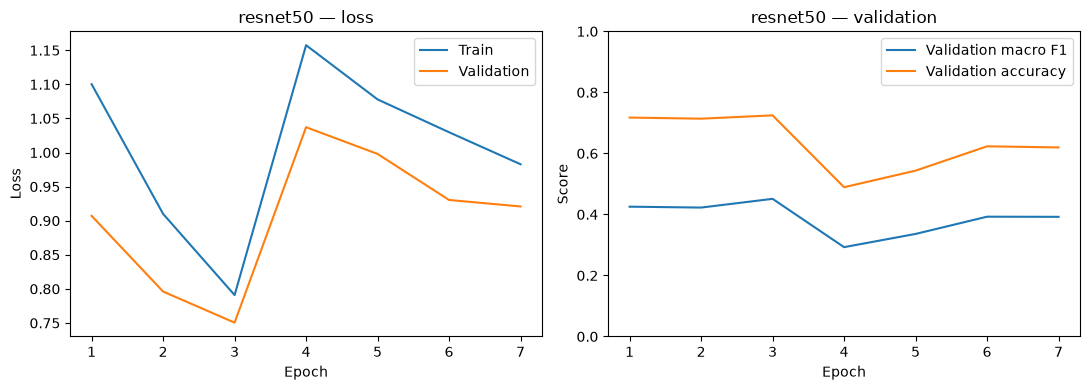

In [4]:
from pathlib import Path
import matplotlib.pyplot as plt
root=Path('results_v2')/MODEL
h=pd.read_csv(root/'history.csv')
fig, ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(h.epoch,h.train_loss,label='Train');ax[0].plot(h.epoch,h.val_loss,label='Validation')
ax[0].set(xlabel='Epoch',ylabel='Loss',title=f'{MODEL} — loss');ax[0].legend()
ax[1].plot(h.epoch,h.val_macro_f1,label='Validation macro F1')
ax[1].plot(h.epoch,h.val_accuracy,label='Validation accuracy')
ax[1].set(xlabel='Epoch',ylabel='Score',title=f'{MODEL} — validation',ylim=(0,1));ax[1].legend()
fig.tight_layout();fig.savefig(root/'learning_curves.png',dpi=300);plt.show()